# Notebook 02 — Data Preparation

**Bước 3 trong Industrial AI lifecycle.** Yêu cầu của đồ án: *giải thích **tại sao** thực hiện từng bước*.

Mỗi mục dưới đây trình bày theo cùng một khuôn: **Làm gì → Tại sao → Bằng chứng từ dữ liệu → Quyết định**.

| # | Bước chuẩn bị dữ liệu | Mục |
|---|---|---|
| 1 | Tạo nhãn RUL (piecewise-linear) | 1 |
| 2 | Chia train / validation **theo động cơ** | 2 |
| 3 | Missing-value treatment | 3 |
| 4 | Outlier treatment | 4 |
| 5 | Feature selection | 5 |
| 6 | Normalization / scaling | 6 |
| 7 | Feature engineering | 7 |
| 8 | Dimensionality reduction (nếu cần) | 8 |
| 9 | Xử lý imbalance (nếu có) | 9 |
| 10 | Lưu dữ liệu đã chuẩn bị | 10 |

In [1]:
import os, sys

REPO_URL = "https://github.com/duyenphung206-sudo/turbofan-rul-prediction.git"
REPO_NAME = "turbofan-rul-prediction"

# Dua thu muc lam viec ve goc du an: VS Code mo tu notebooks/, Colab tai du an tu GitHub
if not os.path.exists("src"):
    if os.path.exists("../src"):
        os.chdir("..")
    else:
        if not os.path.exists(REPO_NAME):
            os.system(f"git clone -q {REPO_URL}")
        os.chdir(REPO_NAME)
        os.system("pip install -q scikit-learn==1.9.1")   # trung phien ban luc luu mo hinh
sys.path.append(os.getcwd())
print("Thu muc lam viec:", os.getcwd())

Thu muc lam viec: /tmp/nbfix


In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler

from src.rul_utils import (
    load_cmapss, load_rul, add_train_rul, add_test_rul, prepare_features, feature_names,
    regression_metrics, save_json, SENSOR_COLS, SETTING_COLS, SENSOR_INFO,
    RUL_CAP, ROLL_WINDOW, SEQ_LEN, ALERT_CRITICAL, RANDOM_STATE,
    set_plot_style, save_fig, BLUE, MUTED, INK,
)

set_plot_style()

train_raw = load_cmapss("data/raw/train_FD001.txt")
test_raw = load_cmapss("data/raw/test_FD001.txt")
rul_test = load_rul("data/raw/RUL_FD001.txt")
print("train:", train_raw.shape, "| test:", test_raw.shape)

train: (20631, 26) | test: (13096, 26)


## 1. Tạo nhãn RUL (piecewise-linear)

**Làm gì:** với mỗi động cơ train, `RUL = chu kỳ cuối − chu kỳ hiện tại`, sau đó **giới hạn trên ở 125 chu kỳ**.

**Tại sao:**
- Dữ liệu gốc không có cột RUL. Vì tập train chạy đến lúc hỏng nên RUL tính được chính xác từ chu kỳ cuối.
- Ở giai đoạn đầu động cơ còn khỏe, cảm biến **chưa có dấu hiệu xuống cấp** (xem Notebook 01, hình xu hướng cảm biến). Bắt mô hình phân biệt "còn 300 chu kỳ" với "còn 200 chu kỳ" khi tín hiệu giống hệt nhau là vô nghĩa và làm tăng sai số. Vì vậy RUL được coi là hằng số (= 125) khi động cơ còn khỏe, và chỉ giảm tuyến tính khi bắt đầu xuống cấp. Cách gán nhãn này do Heimes (PHM 2008) đề xuất và được dùng rộng rãi cho C-MAPSS.
- Về mặt công nghiệp: khi RUL > 125 chu kỳ thì quyết định luôn là "tiếp tục vận hành", nên không cần độ chính xác cao ở vùng này.

Da luu hinh: reports/figures/02_rul_label.png


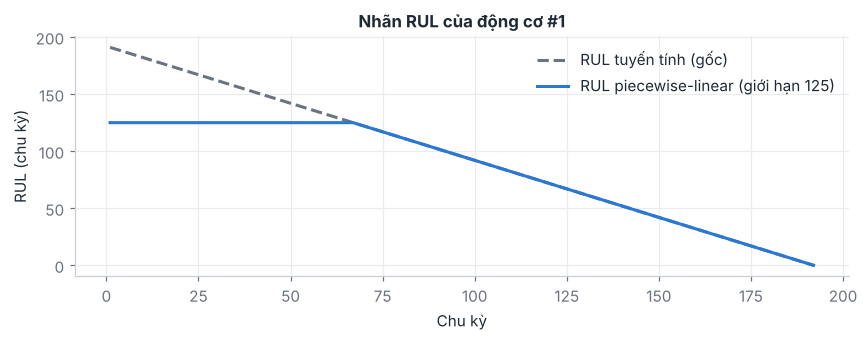

In [3]:
train = add_train_rul(train_raw, cap=RUL_CAP)            # them cot RUL_raw va RUL (da gioi han)
test = add_test_rul(test_raw, rul_test, cap=RUL_CAP)     # tap test: RUL = RUL cuoi (NASA cung cap) + so chu ky con lai

g = train[train["unit"] == 1]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(g["cycle"], g["RUL_raw"], color=MUTED, linestyle="--", label="RUL tuyến tính (gốc)")
ax.plot(g["cycle"], g["RUL"], color=BLUE, label=f"RUL piecewise-linear (giới hạn {RUL_CAP})")
ax.set(title="Nhãn RUL của động cơ #1", xlabel="Chu kỳ", ylabel="RUL (chu kỳ)")
ax.legend()
fig.tight_layout()
save_fig(fig, "02_rul_label.png")
plt.show()

## 2. Chia train / validation **theo động cơ** (group-based split)

**Làm gì:** chọn ngẫu nhiên 20/100 động cơ làm validation; **toàn bộ** chu kỳ của một động cơ nằm trọn trong một tập. Tập test là tập riêng do NASA cung cấp.

**Tại sao:** các dòng của cùng một động cơ rất giống nhau (chu kỳ 100 và 101 gần như trùng). Nếu chia ngẫu nhiên theo dòng, mô hình sẽ "nhìn thấy" động cơ validation trong lúc train → kết quả validation đẹp giả tạo. Bài giảng 03 gọi đây là **information leakage** và khuyến nghị *group-based split* khi dữ liệu gồm nhiều máy.

| Tập | Vai trò | Số động cơ |
|---|---|---|
| Train | Học tham số mô hình | 80 |
| Validation | Chọn cấu hình / siêu tham số, early stopping | 20 |
| Test (NASA) | Đánh giá cuối cùng, **chỉ dùng một lần** ở Notebook 04 | 100 |

In [4]:
rng = np.random.RandomState(RANDOM_STATE)
val_units = sorted(rng.choice(train["unit"].unique(), size=20, replace=False).tolist())

df_train = train[~train["unit"].isin(val_units)].copy()
df_val = train[train["unit"].isin(val_units)].copy()

print("Dong co validation:", val_units)
print("train:", df_train.shape, "| val:", df_val.shape, "| test:", test.shape)
assert set(df_train["unit"]) & set(df_val["unit"]) == set()   # khong dong co nao nam o ca 2 tap

Dong co validation: [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]
train: (16561, 28) | val: (4070, 28) | test: (13096, 28)


## 3. Missing-value treatment

**Bằng chứng:** FD001 **không có** giá trị thiếu (dữ liệu mô phỏng).

**Quyết định:** không cần điền gì cho dữ liệu huấn luyện. **Nhưng** pipeline vẫn có sẵn bước xử lý thiếu, vì dữ liệu thật ngoài nhà máy sẽ có mất kết nối / cảm biến hỏng (chữ **Broken** trong 3B):

- Điền bằng giá trị gần nhất **trước đó** của **cùng động cơ** (forward-fill).

**Tại sao forward-fill chứ không điền trung bình?**
- Cảm biến thay đổi chậm theo chu kỳ → giá trị ngay trước đó là ước lượng tốt nhất.
- Chỉ dùng thông tin **quá khứ** → không rò rỉ thông tin tương lai (đúng nguyên tắc "only information available at prediction time").
- Trung bình toàn bộ sẽ kéo động cơ sắp hỏng về trạng thái "trung bình" → che mất dấu hiệu xuống cấp.

In [5]:
print("So o thieu - train:", int(df_train[SENSOR_COLS].isna().sum().sum()),
      "| val:", int(df_val[SENSOR_COLS].isna().sum().sum()),
      "| test:", int(test[SENSOR_COLS].isna().sum().sum()))

# Minh hoa cach forward-fill hoat dong tren 1 doan du lieu nho bi xoa co y
demo = df_train.loc[df_train["unit"] == 2, ["unit", "cycle", "s_11"]].head(6).copy()
demo.loc[demo.index[[2, 3]], "s_11"] = np.nan                 # gia lap mat tin hieu 2 chu ky
demo["s_11_sau_khi_dien"] = demo.groupby("unit")["s_11"].ffill()
demo

So o thieu - train: 0 | val: 0 | test: 0


,unit,cycle,s_11,s_11_sau_khi_dien
192,2,1,46.93,46.93
193,2,2,47.24,47.24
194,2,3,NaN,47.24
195,2,4,NaN,47.24
196,2,5,47.25,47.25
197,2,6,47.05,47.05


## 4. Outlier treatment

**Làm gì:** đếm các điểm lệch quá 3 độ lệch chuẩn (|z| > 3) của từng cảm biến và xem chúng xuất hiện **ở đâu** trong vòng đời động cơ.

**Tại sao phải xem "ở đâu":** bài giảng 02 nhấn mạnh *"Outliers: Error or Signal?"* — một giá trị cực trị có thể là lỗi đo, nhưng cũng có thể là **sự kiện công nghiệp thật** (động cơ sắp hỏng).

So dong co it nhat 1 outlier: 725 / 16561 (4.4%)
Trong do, ti le nam o 30 chu ky cuoi truoc khi hong: 97.1%
(So sanh: 30 chu ky cuoi chi chiem 15.0% tong so dong)
Da luu hinh: reports/figures/02_outliers_vs_rul.png


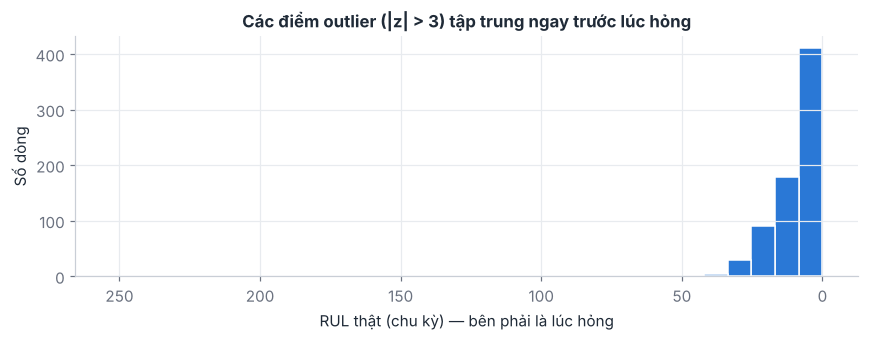

In [6]:
varying = [s for s in SENSOR_COLS if df_train[s].nunique() > 2]      # 14 cam bien co bien thien
z = (df_train[varying] - df_train[varying].mean()) / df_train[varying].std()
is_outlier = z.abs() > 3

rows_with_outlier = is_outlier.any(axis=1)
print(f"So dong co it nhat 1 outlier: {rows_with_outlier.sum()} / {len(df_train)} ({rows_with_outlier.mean() * 100:.1f}%)")
print(f"Trong do, ti le nam o {ALERT_CRITICAL} chu ky cuoi truoc khi hong: "
      f"{(df_train.loc[rows_with_outlier, 'RUL_raw'] <= ALERT_CRITICAL).mean() * 100:.1f}%")
print(f"(So sanh: {ALERT_CRITICAL} chu ky cuoi chi chiem {(df_train['RUL_raw'] <= ALERT_CRITICAL).mean() * 100:.1f}% tong so dong)")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df_train.loc[rows_with_outlier, "RUL_raw"], bins=30, color=BLUE, edgecolor="white")
ax.invert_xaxis()
ax.set(title="Các điểm outlier (|z| > 3) tập trung ngay trước lúc hỏng", xlabel="RUL thật (chu kỳ) — bên phải là lúc hỏng", ylabel="Số dòng")
fig.tight_layout()
save_fig(fig, "02_outliers_vs_rul.png")
plt.show()

**Quyết định: không loại outlier.**

**Tại sao:** phần lớn outlier nằm ở những chu kỳ cuối trước khi hỏng → đó là **tín hiệu xuống cấp** (signal), không phải lỗi đo. Loại bỏ chúng đồng nghĩa với xóa đúng phần dữ liệu quan trọng nhất của bài toán RUL. Nhiễu ngẫu nhiên từng điểm được xử lý bằng trung bình trượt ở mục 7 thay vì xóa dữ liệu.

## 5. Feature selection

**Làm gì:** loại 7 cảm biến hằng số / gần hằng số và 3 thông số vận hành; giữ 14 cảm biến.

**Tại sao:**
- Cột hằng số có phương sai = 0 → không giúp phân biệt động cơ khỏe với động cơ sắp hỏng, chỉ làm mô hình nặng thêm.
- Trong FD001 chỉ có **một** điều kiện vận hành, nên `setting_1..3` gần như cố định và tương quan ≈ 0 với RUL (Notebook 01).
- Ít đặc trưng hơn → mô hình nhẹ hơn, dễ giải thích hơn cho kỹ sư bảo trì (ràng buộc công nghiệp).

**Lưu ý chống leakage:** quy tắc chọn được tính **chỉ trên tập train**.

In [7]:
n_unique = df_train[SENSOR_COLS].nunique()
dropped_sensors = n_unique[n_unique <= 2].index.tolist()      # hang so hoac chi co 2 gia tri
sensors = [s for s in SENSOR_COLS if s not in dropped_sensors]

print("Loai bo  :", dropped_sensors, "+", SETTING_COLS)
print("Giu lai  :", sensors, f"({len(sensors)} cam bien)")
pd.DataFrame({"Ky hieu": [SENSOR_INFO[s][0] for s in sensors],
              "Y nghia": [SENSOR_INFO[s][1] for s in sensors]}, index=sensors)

Loai bo  : ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19'] + ['setting_1', 'setting_2', 'setting_3']
Giu lai  : ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21'] (14 cam bien)


,Ky hieu,Y nghia
s_2,T24,Nhiệt độ tại cửa ra LPC
s_3,T30,Nhiệt độ tại cửa ra HPC
s_4,T50,Nhiệt độ tại cửa ra LPT
s_7,P30,Áp suất tổng tại cửa ra HPC
s_8,Nf,Tốc độ quay vật lý của quạt
s_9,Nc,Tốc độ quay vật lý của lõi
s_11,Ps30,Áp suất tĩnh tại cửa ra HPC
s_12,phi,Tỉ số lưu lượng nhiên liệu / Ps30
s_13,NRf,Tốc độ quạt hiệu chỉnh
s_14,NRc,Tốc độ lõi hiệu chỉnh


## 6. Normalization / scaling

**Làm gì:** đưa 14 cảm biến về khoảng [0, 1] bằng `MinMaxScaler`; scaler được **fit chỉ trên tập train**, rồi áp dụng cho validation, test và dữ liệu mới trong app.

**Tại sao:**
- Thang đo rất khác nhau (`s_9` ≈ 9000, `s_15` ≈ 8.4). Linear Regression và đặc biệt LSTM (học bằng gradient) sẽ bị cảm biến có trị số lớn chi phối nếu không scale.
- Fit trên toàn bộ dữ liệu (kể cả validation/test) là **information leakage**: "computing preprocessing parameters using the entire dataset" (bài giảng 03).
- Random Forest không cần scaling, nhưng dùng chung một bảng đặc trưng cho cả 3 mô hình giúp so sánh công bằng và pipeline đơn giản.

In [8]:
scaler = MinMaxScaler().fit(df_train[sensors])          # chi fit tren train

before = df_train[sensors].agg(["min", "max"]).T
after = pd.DataFrame(scaler.transform(df_val[sensors]), columns=sensors).agg(["min", "max"]).T
pd.concat([before.add_prefix("train_goc_"), after.add_prefix("val_sau_scale_")], axis=1).round(3)

,train_goc_min,train_goc_max,val_sau_scale_min,val_sau_scale_max
s_2,641.210,644.530,0.012,0.973
s_3,1571.040,1616.910,0.017,0.957
s_4,1385.190,1441.490,-0.052,0.936
s_7,549.850,556.060,0.081,0.923
s_8,2387.900,2388.560,0.030,0.667
s_9,9021.730,9244.590,0.052,0.648
s_11,46.850,48.520,0.030,1.006
s_12,518.690,523.380,0.079,0.942
s_13,2387.880,2388.560,0.029,0.706
s_14,8099.940,8293.720,0.057,0.676


**Nhận xét:** sau khi scale, dữ liệu validation nằm gần trọn trong [0, 1] (có thể hơi vượt ra ngoài vì scaler không "nhìn thấy" validation — đó là hành vi đúng).

## 7. Feature engineering

**Làm gì:** với mỗi cảm biến, tính thêm theo **từng động cơ**:
- `*_mean`: trung bình trượt của `window` chu kỳ gần nhất → xu hướng đã lọc nhiễu;
- `*_std`: độ lệch chuẩn trượt → mức dao động gần đây.

**Tại sao:**
- Nhiễu cảm biến ≈ 6% biên độ (Notebook 01) che khuất xu hướng. Linear Regression và Random Forest xử lý từng dòng độc lập, **không biết gì về quá khứ**; đặc trưng trượt là cách đơn giản để đưa "trí nhớ ngắn hạn" vào cho hai mô hình này.
- Cửa sổ trượt chỉ nhìn về **quá khứ** → dùng được lúc vận hành thật.
- LSTM tự học quan hệ thời gian nên chỉ dùng 14 cảm biến đã scale (chuỗi 30 chu kỳ), không cần các cột trượt.

**Chọn `window` thế nào?** So sánh nhanh bằng RMSE trên **validation** (không đụng tới test) với một mô hình đơn giản (Linear Regression).

In [9]:
rows = []
for window in [5, 10, 20, 30]:
    f_tr = prepare_features(df_train, sensors, scaler, window)
    f_va = prepare_features(df_val, sensors, scaler, window)
    feats = feature_names(sensors)
    lr = LinearRegression().fit(f_tr[feats], f_tr["RUL"])
    pred = np.clip(lr.predict(f_va[feats]), 0, RUL_CAP)
    rows.append({"window": window, "RMSE_validation": regression_metrics(f_va["RUL"], pred)["RMSE"]})

# Moc so sanh: chi dung 14 cam bien da scale, khong co dac trung truot
lr0 = LinearRegression().fit(f_tr[sensors], f_tr["RUL"])
rmse0 = regression_metrics(f_va["RUL"], np.clip(lr0.predict(f_va[sensors]), 0, RUL_CAP))["RMSE"]
print(f"Khong co dac trung truot: RMSE validation = {rmse0:.2f}")
pd.DataFrame(rows).round(2)

Khong co dac trung truot: RMSE validation = 19.90


,window,RMSE_validation
0,5,19.45
1,10,19.38
2,20,18.91
3,30,18.18


**Quyết định:** `window = 30` cho RMSE validation thấp nhất và **bằng đúng độ dài chuỗi đầu vào của LSTM** (30 chu kỳ) → ba mô hình cùng được "nhìn" 30 chu kỳ gần nhất, so sánh công bằng.

So dac trung cho Linear Regression / Random Forest: 42 (14 goc + 14 mean + 14 std)


Da luu hinh: reports/figures/02_rolling_feature.png


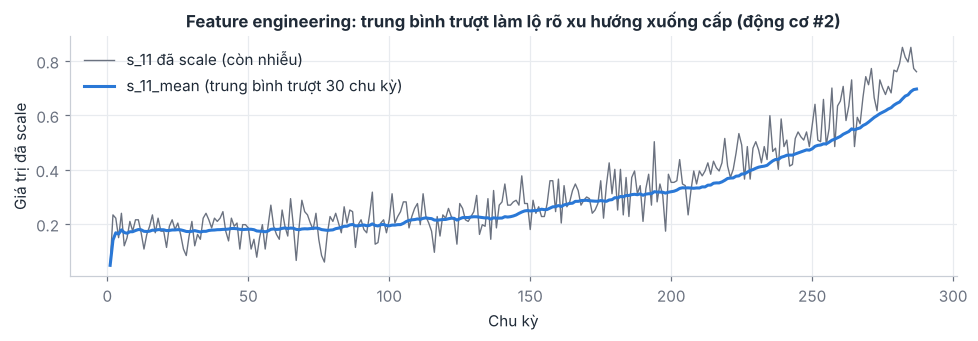

In [10]:
WINDOW = ROLL_WINDOW        # = 30, khai bao trong src/rul_utils.py
assert WINDOW == 30

feat_train = prepare_features(df_train, sensors, scaler, WINDOW)
feat_val = prepare_features(df_val, sensors, scaler, WINDOW)
feat_test = prepare_features(test, sensors, scaler, WINDOW)
features = feature_names(sensors)
print("So dac trung cho Linear Regression / Random Forest:", len(features), "(14 goc + 14 mean + 14 std)")

g = feat_train[feat_train["unit"] == 2]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(g["cycle"], g["s_11"], color=MUTED, linewidth=0.9, label="s_11 đã scale (còn nhiễu)")
ax.plot(g["cycle"], g["s_11_mean"], color=BLUE, label=f"s_11_mean (trung bình trượt {WINDOW} chu kỳ)")
ax.set(title="Feature engineering: trung bình trượt làm lộ rõ xu hướng xuống cấp (động cơ #2)", xlabel="Chu kỳ", ylabel="Giá trị đã scale")
ax.legend()
fig.tight_layout()
save_fig(fig, "02_rolling_feature.png")
plt.show()

## 8. Dimensionality reduction (nếu cần)

**Làm gì:** chạy thử PCA trên 14 cảm biến đã scale để xem có cần giảm chiều không.

**Tại sao phải kiểm tra:** yêu cầu đồ án ghi "nếu cần" → phải có bằng chứng để quyết định, không làm theo thói quen.

In [11]:
pca = PCA().fit(feat_train[sensors])
explained = np.cumsum(pca.explained_variance_ratio_)
print("Phuong sai tich luy theo so thanh phan chinh:")
print(pd.Series(explained[:6], index=[f"{i} thanh phan dau" for i in range(1, 7)]).round(3).to_string())

Phuong sai tich luy theo so thanh phan chinh:
1 thanh phan dau    0.693
2 thanh phan dau    0.779
3 thanh phan dau    0.810
4 thanh phan dau    0.839
5 thanh phan dau    0.865
6 thanh phan dau    0.889


**Quyết định: không giảm chiều.**

**Tại sao:**
- Chỉ có 14 cảm biến (42 đặc trưng sau feature engineering) với ~16.000 dòng train → không gặp "curse of dimensionality", huấn luyện chỉ mất vài giây.
- PCA trộn các cảm biến thành thành phần trừu tượng → **mất khả năng giải thích** ("PC1 tăng" không có nghĩa với kỹ sư, còn "nhiệt độ T50 tăng" thì có). Khả năng giải thích là một ràng buộc công nghiệp của bài toán.
- PCA cho thấy thành phần đầu tiên đã chiếm phần lớn phương sai → các cảm biến cùng phản ánh **một** quá trình xuống cấp; đây là nhận xét hữu ích, nhưng không phải lý do để bỏ tên cảm biến.

## 9. Xử lý imbalance (nếu có)

**Bài toán là hồi quy** nên không có "lớp" theo nghĩa phân loại. Tuy nhiên có hai dạng mất cân bằng cần xem xét.

Ti le dong co nhan RUL = 125 (dong co con khoe)      : 39.6%
Ti le dong thuoc vung nguy cap (RUL <= 30)           : 15.0%


Da luu hinh: reports/figures/02_rul_distribution.png


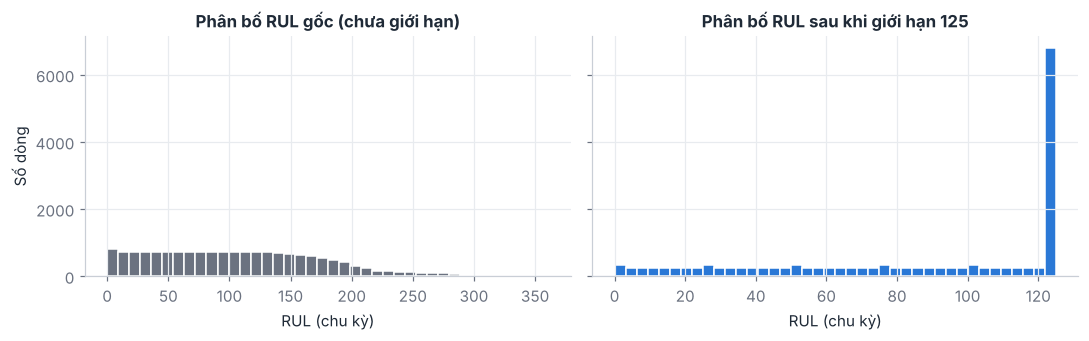

In [12]:
share_cap = (feat_train["RUL"] == RUL_CAP).mean()
share_critical = (feat_train["RUL"] <= ALERT_CRITICAL).mean()
print(f"Ti le dong co nhan RUL = {RUL_CAP} (dong co con khoe)      : {share_cap * 100:.1f}%")
print(f"Ti le dong thuoc vung nguy cap (RUL <= {ALERT_CRITICAL})           : {share_critical * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].hist(df_train["RUL_raw"], bins=40, color=MUTED, edgecolor="white")
axes[0].set(title="Phân bố RUL gốc (chưa giới hạn)", xlabel="RUL (chu kỳ)", ylabel="Số dòng")
axes[1].hist(feat_train["RUL"], bins=40, color=BLUE, edgecolor="white")
axes[1].set(title=f"Phân bố RUL sau khi giới hạn {RUL_CAP}", xlabel="RUL (chu kỳ)")
fig.tight_layout()
save_fig(fig, "02_rul_distribution.png")
plt.show()

**Nhận xét và quyết định:**

| Dạng mất cân bằng | Bằng chứng | Quyết định | Tại sao |
|---|---|---|---|
| Phần lớn dòng dữ liệu là "động cơ còn khỏe" | ≈ 40% số dòng có RUL = 125 | **Không** resampling (không SMOTE, không under-sampling) | Dữ liệu là chuỗi thời gian; lấy mẫu lại theo dòng sẽ phá cấu trúc thời gian. Giới hạn RUL = 125 đã ngăn các giá trị RUL rất lớn chi phối hàm mất mát. |
| Vùng quan trọng nhất cho quyết định (RUL ≤ 30) chỉ chiếm ít dữ liệu | ≈ 15% số dòng | Xử lý ở **khâu đánh giá** | Ngoài RMSE toàn cục, Notebook 04 đánh giá riêng cảnh báo "RUL ≤ 30" bằng Precision / Recall / false-alarm rate (không dùng accuracy), và phân tích sai số theo từng vùng RUL. |

## 10. Lưu dữ liệu đã chuẩn bị

Các file dưới đây là **đầu vào của Notebook 03, 04 và của app**:

| File | Nội dung |
|---|---|
| `data/processed/train_fd001.csv.gz` | 80 động cơ train, 42 đặc trưng + RUL |
| `data/processed/val_fd001.csv.gz` | 20 động cơ validation |
| `data/processed/test_fd001.csv.gz` | 100 động cơ test (mọi chu kỳ) |
| `models/scaler.joblib` | MinMaxScaler đã fit trên train |
| `models/feature_config.json` | Danh sách cảm biến, tham số, thống kê "trạng thái khỏe" để app giải thích và giám sát dữ liệu |

In [13]:
os.makedirs("data/processed", exist_ok=True)
os.makedirs("models", exist_ok=True)

feat_train.round(5).to_csv("data/processed/train_fd001.csv.gz", index=False)
feat_val.round(5).to_csv("data/processed/val_fd001.csv.gz", index=False)
feat_test.round(5).to_csv("data/processed/test_fd001.csv.gz", index=False)
joblib.dump(scaler, "models/scaler.joblib")

# Thong ke "trang thai khoe" (RUL = 125) cua trung binh truot: dung de giai thich
# "cam bien nao dang lech khoi trang thai khoe" trong app
healthy = feat_train[feat_train["RUL"] == RUL_CAP]
mean_cols = [f"{s}_mean" for s in sensors]

config = {
    "dataset": "NASA C-MAPSS FD001",
    "sensors": sensors,
    "dropped_sensors": dropped_sensors,
    "features": features,
    "rul_cap": RUL_CAP,
    "roll_window": WINDOW,
    "seq_len": SEQ_LEN,
    "val_units": val_units,
    "healthy_mean": {s: float(healthy[f"{s}_mean"].mean()) for s in sensors},
    "healthy_std": {s: float(healthy[f"{s}_mean"].std()) for s in sensors},
    "train_raw_min": {s: float(df_train[s].min()) for s in sensors},   # vung du lieu da huan luyen
    "train_raw_max": {s: float(df_train[s].max()) for s in sensors},
}
save_json(config, "models/feature_config.json")
print("Da luu 3 file du lieu, scaler va feature_config.json")
print("Kich thuoc:", feat_train.shape, feat_val.shape, feat_test.shape)

Da luu 3 file du lieu, scaler va feature_config.json
Kich thuoc: (16561, 46) (4070, 46) (13096, 46)


## Tổng kết Bước 3: Data Preparation

| Bước | Đã làm | Tại sao | Kết quả |
|---|---|---|---|
| Nhãn RUL | Piecewise-linear, giới hạn 125 | Động cơ còn khỏe chưa có tín hiệu xuống cấp; quyết định không đổi khi RUL lớn | Cột `RUL` |
| Chia dữ liệu | Group-based theo động cơ: 80 train / 20 validation; test riêng của NASA | Tránh information leakage giữa các chu kỳ của cùng một động cơ | 3 tập độc lập |
| Missing value | Không có giá trị thiếu; pipeline có sẵn forward-fill theo động cơ | Dữ liệu thật sẽ thiếu; forward-fill chỉ dùng quá khứ | Sẵn sàng cho dữ liệu thật |
| Outlier | Không loại | Outlier tập trung trước lúc hỏng → là tín hiệu, không phải lỗi | Giữ nguyên dữ liệu |
| Feature selection | Loại 7 cảm biến hằng số + 3 thông số vận hành | Không mang thông tin trong FD001 | 14 cảm biến |
| Scaling | MinMax [0, 1], fit trên train | Thang đo khác nhau; tránh leakage | `scaler.joblib` |
| Feature engineering | Trung bình trượt + độ lệch chuẩn trượt 30 chu kỳ | Lọc nhiễu, đưa thông tin quá khứ vào mô hình bảng | 42 đặc trưng |
| Dimensionality reduction | Không áp dụng | Số chiều nhỏ; cần giữ khả năng giải thích | — |
| Imbalance | Không resampling; đánh giá riêng vùng RUL ≤ 30 | Giữ cấu trúc chuỗi thời gian; accuracy không phù hợp | Chỉ số ở Notebook 04 |